### Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from msuthemes import theme_msu, colors
import warnings
warnings.simplefilter("ignore")

### Configuration of Paths, Variables, and Load Precomputed Results

In [2]:
RESULTS_DIR = "../data/04_analysis/h1_results/no_prior_exposure"
OUTPUT_PLOT = os.path.join(RESULTS_DIR, "Master_H1_Analysis_no_prior_exposure.png")

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']

signal_titles = { 'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y', 
                 'Pupil_Mean': 'Pupil Dilation', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'}

stats_df = pd.read_csv(os.path.join(RESULTS_DIR, "h1_summary_stats.csv")).set_index('Signal')

### Set up Helper Functions and (Pre)Compute Results

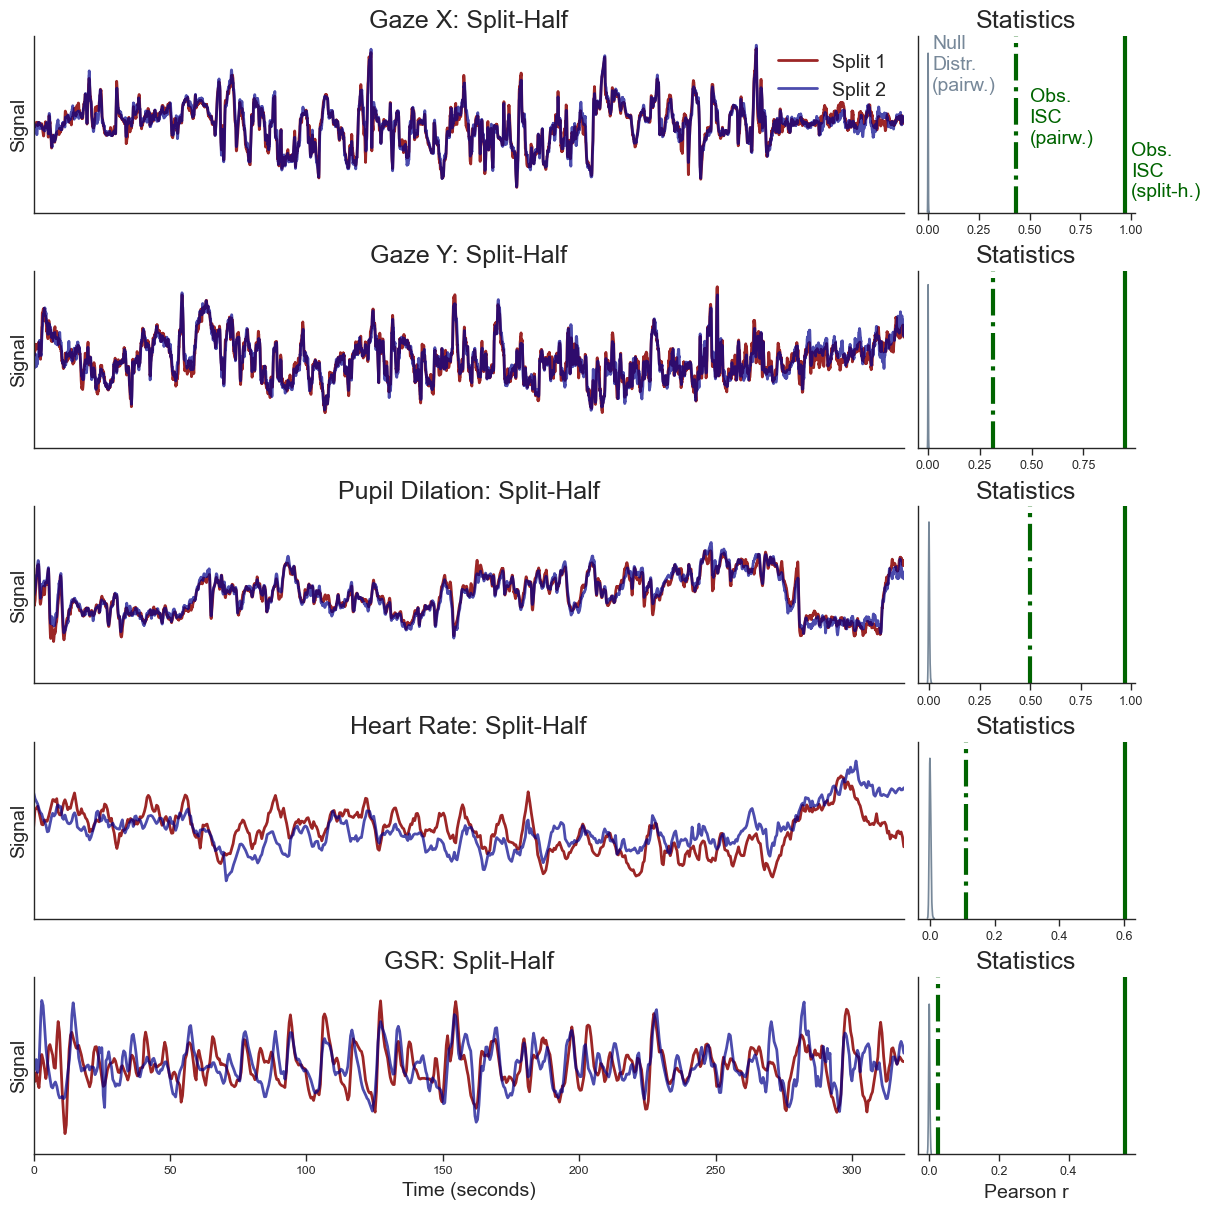

Final Master figure saved to ../data/04_analysis/h1_results/no_prior_exposure/Master_H1_Analysis_no_prior_exposure.png


In [3]:
sns.set_theme(font='Arial')
sns.set(style="ticks", context="paper")
#theme_msu()

# 1. Adjusted Ratio: 2.5 to 1 (Balanced)
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(12, 12), 
                         gridspec_kw={'width_ratios': [4, 1]}, 
                         constrained_layout=True)

for i, signal in enumerate(signals):
    
    # Get stats
    r_split = stats_df.loc[signal, 'Split_Half_r']
    obs_isc = stats_df.loc[signal, 'Observed_ISC']
    p_val   = stats_df.loc[signal, 'Phase_Rand_P']
    
    # ==========================
    # LEFT COLUMN: TIMECOURSE
    # ==========================
    ax_tc = axes[i, 0]
    tc_df = pd.read_csv(os.path.join(RESULTS_DIR, f"{signal}_split_timecourse.csv"))
    
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_1'], color= 'darkred', linestyle='-', lw= 2, alpha = 0.85, label='Split 1')
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_2'], color= 'darkblue', linestyle='-', alpha = 0.7, lw= 2, label='Split 2')
    
    # Title
    ax_tc.set_title(f"{signal_titles[signal]}: Split-Half", fontsize=18, loc='center')
    
    # Clean Y-Axis (Remove Z-score labels)
    ax_tc.set_ylabel("Signal", fontsize=14)   
    ax_tc.set_yticks([])   
    ax_tc.set_ylim([-4.5,4.5])   
    ax_tc.set_xlim(tc_df['Time_Sec'].min(), tc_df['Time_Sec'].max())
    
    # Clean X-Axis (Only show on bottom row)
    if i < 4: 
        ax_tc.set_xticklabels([])
        ax_tc.set_xlabel("")
        ax_tc.tick_params(bottom=False) # Hide the tick marks too
    else: 
        ax_tc.set_xlabel("Time (seconds)", fontsize=14)


    # ==========================
    # RIGHT COLUMN: HISTOGRAMS
    # ==========================
    ax_null = axes[i, 1]
    null_dist = np.load(os.path.join(RESULTS_DIR, f"{signal}_null_dist.npy"))
    
    sns.histplot(null_dist, kde=True, color='lightslategrey', alpha=0.5, ax=ax_null, label='Null Distr.')
    ax_null.axvline(obs_isc, color= 'darkgreen', linestyle='-.', linewidth=3, label='Obs. ISC (pairw.)')
    ax_null.axvline(r_split, color= 'darkgreen', linestyle='-', linewidth=3, label='Obs. ISC (split-h.)')
    
    # Title
    ax_null.set_title(f"Statistics",  fontsize=18, loc='center')
    
    # Clean Y-Axis
    ax_null.set_ylabel("") 
    ax_null.set_yticks([]) 
    
    # KEEP X-Axis for ALL rows (because scales differ)
    ax_null.tick_params(axis='x', labelsize=9) # Make numbers slightly smaller to fit
    # We only label the axis text on the bottom to save vertical space, 
    # but we keep the numbers (ticks) on all rows.
    if i == 4:
        ax_null.set_xlabel("Pearson r", fontsize=14)
    else:
        ax_null.set_xlabel("")

# --- FINAL TOUCHES ---
# Legends (First row only)
axes[0,0].legend(loc='upper right',   fontsize=14, frameon=False)
#axes[0,1].legend(loc='upper right',  fontsize=14, frameon=False)
axes[0,1].text(0.02, 230, "Null\nDistr.\n(pairw.)", fontsize=14, color='lightslategrey')
axes[0,1].text(0.5, 130, "Obs.\nISC\n(pairw.)", fontsize=14, color = 'darkgreen')
axes[0,1].text(1., 30, "Obs.\nISC\n(split-h.)", fontsize=14, color = 'darkgreen')


sns.despine()

plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Final Master figure saved to {OUTPUT_PLOT}")